# TP 2 : Histogramme et Seuillage d'Image

**Plan**
- Exercice 1 : étude de l'histogramme (analyse, étirement linéaire, égalisation)
- Exercice 2 : seuillage (global fixe, Otsu, adaptatif moyenne / gaussien)
- Exercice 3 : tableau récapitulatif des méthodes
- Exercice 4 : CLAHE + seuillage
- Problème : contrôle qualité industriel (Partie 1 : analyse et conception, Partie 2 : implémentation)

> **Utiliser votre propre image :** mettez le chemin dans `IMAGE_PATH` (cellule 2).
> Sinon, le notebook génère des images synthétiques (sombre, claire, peu contrastée, éclairage inégal)
> avec un *masque de vérité terrain*, ce qui permet de mesurer objectivement la qualité de chaque méthode.

In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import os

plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 10

## 0. Chargement de l'image

`IMAGE_PATH = None` utilise une image synthétique. Sinon indiquez par exemple `"image.jpg"`.

In [3]:
# IMAGE_PATH = "./image.png"   # ex: "mon_image.jpg"

IMAGE_PATH = None

def make_scene(lo, hi, noise=3.0, uneven=False, seed=0):
    """Scène 'produit sur fond' + masque de vérité terrain.
    lo, hi : plage de niveaux de gris occupée (simule sombre / claire / peu contrastée)."""
    rng = np.random.default_rng(seed)
    h, w = 300, 400
    base = np.zeros((h, w), np.float32)
    cv2.circle(base, (110, 150), 60, 1, -1)
    cv2.rectangle(base, (230, 70), (350, 190), 1, -1)
    cv2.ellipse(base, (290, 245), (50, 25), 20, 0, 360, 1, -1)
    gt = (base > 0.5).astype(np.uint8) * 255
    base = cv2.GaussianBlur(base, (7, 7), 0)
    img = 0.25 + 0.5 * base                      # objet plus clair que le fond
    if uneven:                                   # gradient d'éclairage
        illum = np.tile(np.linspace(0.35, 1.0, w, dtype=np.float32), (h, 1))
        img = img * illum
    img = (img - img.min()) / (img.max() - img.min())
    img = lo + img * (hi - lo)
    img = img + rng.normal(0, noise, img.shape)
    return np.clip(img, 0, 255).astype(np.uint8), gt

def make_document(seed=1):
    """Document scanné mal éclairé (texte sombre, papier clair, gradient + bruit)."""
    rng = np.random.default_rng(seed)
    h, w = 300, 400
    txt = np.zeros((h, w), np.uint8)
    for i, line in enumerate(["Histogramme", "Seuillage Otsu", "Adaptatif", "CLAHE TP 2", "Controle qualite"]):
        cv2.putText(txt, line, (20, 50 + i * 50), cv2.FONT_HERSHEY_SIMPLEX, 1.0, 1, 2, cv2.LINE_AA)
    txt = txt.astype(np.float32)
    illum = np.tile(np.linspace(0.25, 1.0, w, dtype=np.float32), (h, 1))
    img = illum * (0.95 - 0.55 * txt) * 255
    img = img + rng.normal(0, 4, img.shape)
    return np.clip(img, 0, 255).astype(np.uint8)

CONDITIONS = {
    "sombre":           dict(lo=15,  hi=75),
    "claire":           dict(lo=175, hi=245),
    "faible contraste": dict(lo=105, hi=145),
    "éclairage inégal": dict(lo=10,  hi=230, uneven=True),
}
SCENES = {name: make_scene(**p, seed=i) for i, (name, p) in enumerate(CONDITIONS.items())}
DOC = make_document()

if IMAGE_PATH and os.path.exists(IMAGE_PATH):
    img = cv2.imread(IMAGE_PATH, cv2.IMREAD_GRAYSCALE)
    print("Image chargée :", IMAGE_PATH, img.shape)
else:
    img, _ = SCENES["faible contraste"]
    print("Image synthétique (faible contraste) :", img.shape)
print("min / max / moyenne / écart-type :", img.min(), img.max(), round(img.mean(), 1), round(img.std(), 1))

Image synthétique (faible contraste) : (300, 400)
min / max / moyenne / écart-type : 92 159 114.5 17.2


In [4]:
def show(images, titles, hist=True, cdf=False, figsize=None):
    """Affiche une rangée d'images et, dessous, leurs histogrammes."""
    n = len(images)
    rows = 2 if hist else 1
    fig, axes = plt.subplots(rows, n, figsize=figsize or (4 * n, 3.2 * rows), squeeze=False)
    for j, (im, t) in enumerate(zip(images, titles)):
        axes[0, j].imshow(im, cmap="gray", vmin=0, vmax=255)
        axes[0, j].set_title(t)
        axes[0, j].axis("off")
        if hist:
            ax = axes[1, j]
            ax.hist(im.ravel(), bins=256, range=(0, 256), color="steelblue")
            ax.set_xlim(0, 255)
            ax.set_xlabel("niveau de gris")
            if cdf:
                h, _ = np.histogram(im.ravel(), bins=256, range=(0, 256))
                c = np.cumsum(h) / h.sum()
                ax2 = ax.twinx()
                ax2.plot(c, color="crimson")
                ax2.set_ylim(0, 1.02)
                ax2.set_yticks([])
    plt.tight_layout()
    plt.show()

# Exercice 1 : Étude de l'histogramme

## 1.1 Affichage et analyse

L'histogramme `h(k)` compte le nombre de pixels de niveau `k`. Ce qu'on lit dessus :
- **position** du pic → luminosité (pic à gauche = sombre, à droite = clair)
- **largeur** → contraste (étroit = faible contraste, étalé = bon contraste)
- **nombre de modes** → bimodal = objet + fond (bon candidat pour Otsu)

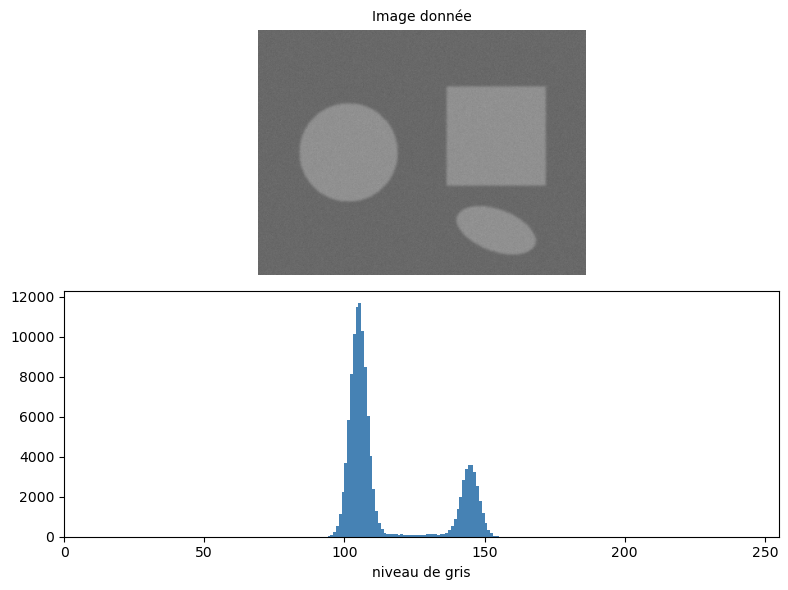

Plage utilisée : [92, 159]  -> 68 niveaux sur 256
Moyenne = 114.5 | écart-type = 17.2 | percentiles 2-98 : [99, 149]
Diagnostic : histogramme ÉCRASÉ (faible contraste).
Diagnostic : luminosité moyenne, centrée.


In [5]:
show([img], ["Image donnée"], figsize=(8, 6))

p2, p98 = np.percentile(img, [2, 98])
print(f"Plage utilisée : [{img.min()}, {img.max()}]  -> {img.max() - img.min() + 1} niveaux sur 256")
print(f"Moyenne = {img.mean():.1f} | écart-type = {img.std():.1f} | percentiles 2-98 : [{p2:.0f}, {p98:.0f}]")

if img.std() < 30:
    print("Diagnostic : histogramme ÉCRASÉ (faible contraste).")
if img.mean() < 85:
    print("Diagnostic : image SOMBRE (masse à gauche).")
elif img.mean() > 170:
    print("Diagnostic : image CLAIRE (masse à droite).")
else:
    print("Diagnostic : luminosité moyenne, centrée.")

## 1.2 Étirement linéaire (contrast stretching)

$$ g(x,y) = 255 \cdot \frac{f(x,y) - f_{min}}{f_{max} - f_{min}} $$

C'est une transformation **linéaire** : la forme de l'histogramme est conservée, il est seulement étiré.
Version robuste : on remplace `min`/`max` par les percentiles 2 % / 98 % pour ignorer les pixels aberrants.

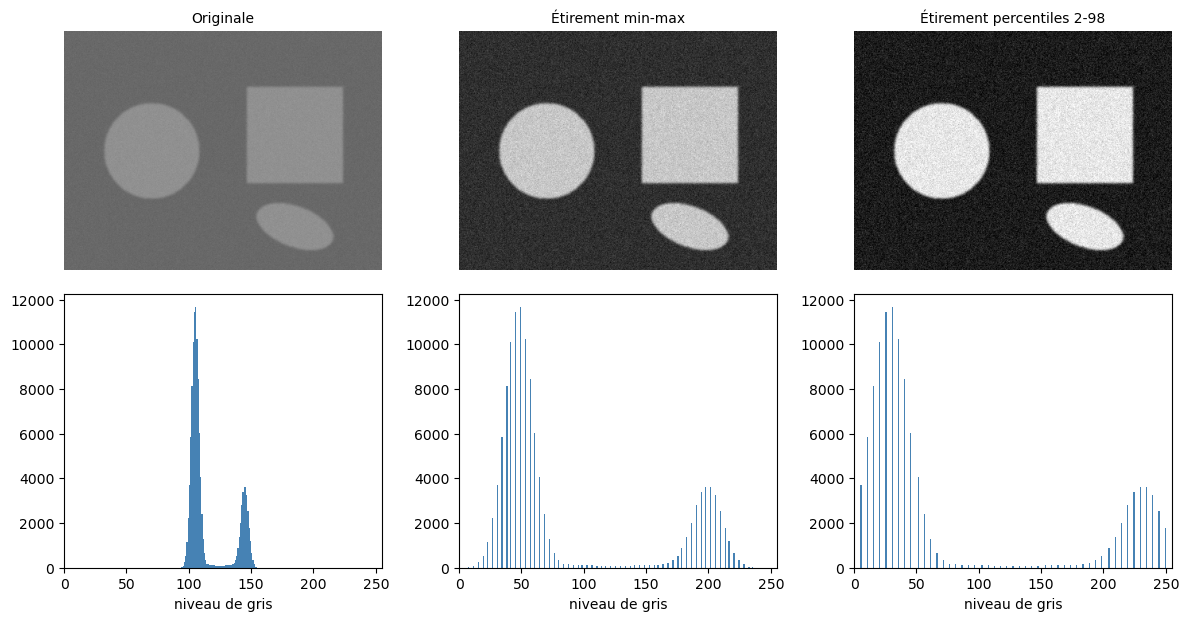

Originale    écart-type =   17.2
Min-max      écart-type =   65.6
Percentiles  écart-type =   87.5


In [6]:
def stretch(im, low=None, high=None):
    low = im.min() if low is None else low
    high = im.max() if high is None else high
    out = (im.astype(np.float32) - low) / max(high - low, 1) * 255
    return np.clip(out, 0, 255).astype(np.uint8)

img_stretch = stretch(img)
img_stretch_p = stretch(img, *np.percentile(img, [2, 98]))

show([img, img_stretch, img_stretch_p],
     ["Originale", "Étirement min-max", "Étirement percentiles 2-98"])
for name, im in [("Originale", img), ("Min-max", img_stretch), ("Percentiles", img_stretch_p)]:
    print(f"{name:12s} écart-type = {im.std():6.1f}")

## 1.3 Égalisation d'histogramme

On utilise la fonction de répartition cumulée (CDF, courbe rouge) comme transformation :

$$ g = \text{round}\left(255 \cdot \frac{CDF(f) - CDF_{min}}{N - CDF_{min}}\right) $$

Contrairement à l'étirement, c'est **non linéaire** : les niveaux très peuplés sont écartés, les niveaux rares sont resserrés. L'histogramme visé est *plat*.
Implémentation manuelle puis vérification avec OpenCV :

Écart max manuel vs OpenCV : 0


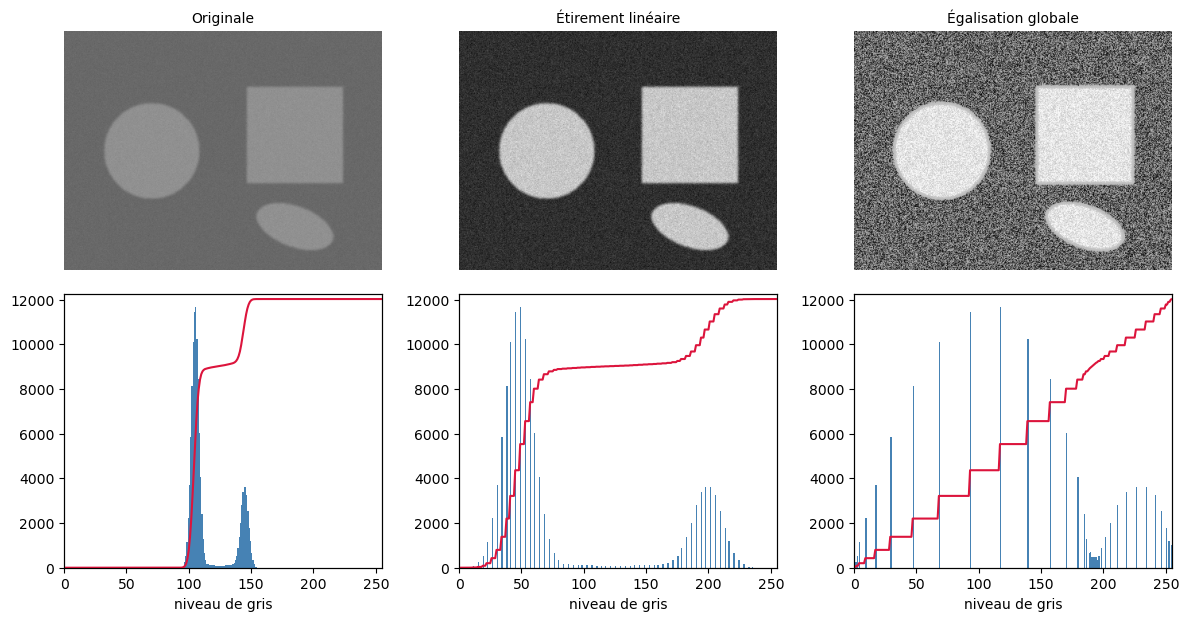

In [7]:
def equalize_manual(im):
    hist, _ = np.histogram(im.ravel(), bins=256, range=(0, 256))
    cdf = hist.cumsum()
    cdf_min = cdf[cdf > 0][0]
    lut = np.round((cdf - cdf_min) / (cdf[-1] - cdf_min) * 255).clip(0, 255).astype(np.uint8)
    return lut[im]

img_eq_manual = equalize_manual(img)
img_eq = cv2.equalizeHist(img)
print("Écart max manuel vs OpenCV :", np.abs(img_eq.astype(int) - img_eq_manual.astype(int)).max())

show([img, img_stretch, img_eq],
     ["Originale", "Étirement linéaire", "Égalisation globale"], cdf=True)

### Comparaison étirement / égalisation

| | Étirement linéaire | Égalisation |
|---|---|---|
| Transformation | linéaire (affine) | non linéaire (CDF) |
| Forme de l'histogramme | conservée | aplatie |
| Effet sur le bruit | amplifié proportionnellement | peut être fortement amplifié dans les zones homogènes |
| Risque | aucun artefact, mais contraste limité si l'histogramme est multimodal | sur-contraste, aspect « artificiel » |

Remarque : l'égalisation produit un histogramme *creux* (peigne) car on ne peut pas créer de nouveaux niveaux : on ne fait que déplacer ceux qui existent.

# Exercice 2 : Seuillage

Seuillage : `g(x,y) = 255 si f(x,y) > T, sinon 0`. Tout l'enjeu est le choix de `T`.

Images utilisées : la scène (éclairage homogène) et le **document mal éclairé** (gradient + texte), pour que les différences entre méthodes soient visibles.

## 2.1 Seuillage global fixe

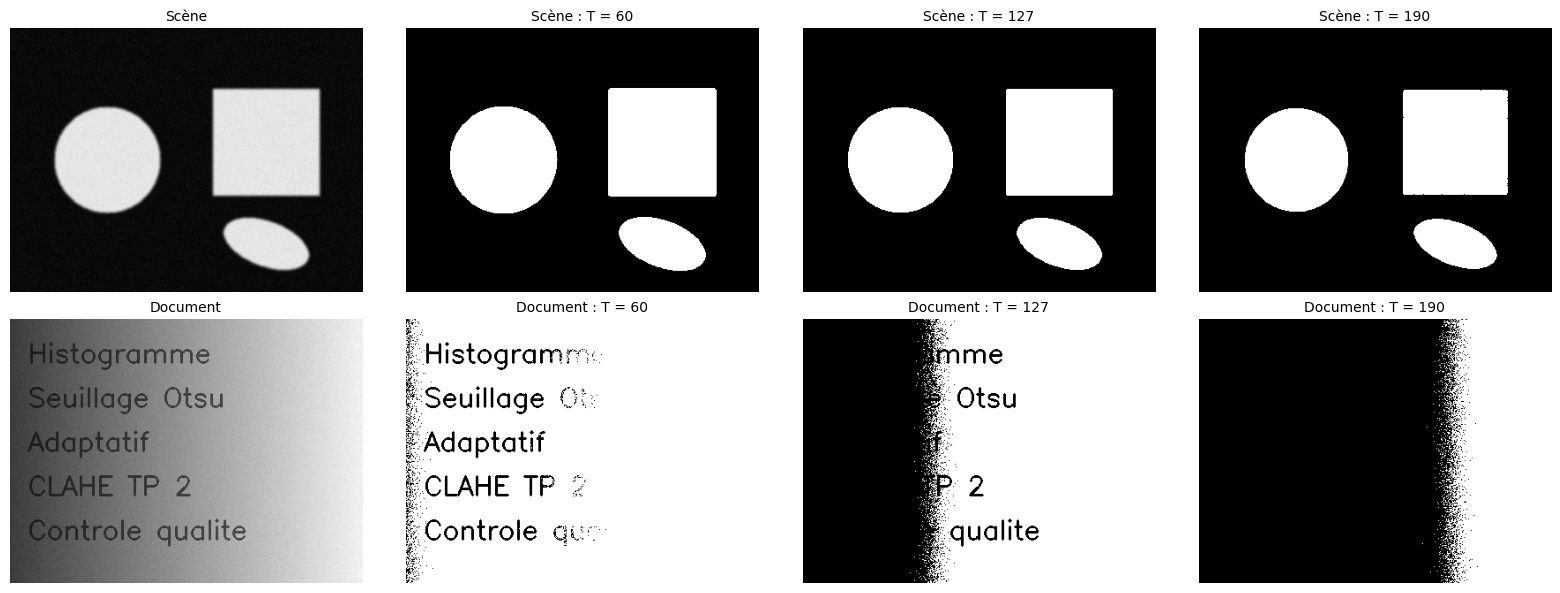

In [8]:
scene, scene_gt = make_scene(lo=10, hi=230, noise=4, seed=42)   # bon contraste, éclairage homogène

def thr_global(im, T=127):
    _, out = cv2.threshold(im, T, 255, cv2.THRESH_BINARY)
    return out

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for row, (name, im) in enumerate([("Scène", scene), ("Document", DOC)]):
    axes[row, 0].imshow(im, cmap="gray", vmin=0, vmax=255); axes[row, 0].set_title(name)
    for k, T in enumerate([60, 127, 190], start=1):
        axes[row, k].imshow(thr_global(im, T), cmap="gray"); axes[row, k].set_title(f"{name} : T = {T}")
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

**Observation :** un `T` fixe est fragile. Il marche sur la scène seulement si `T` tombe dans la vallée de l'histogramme, et il échoue sur le document car l'éclairage varie d'un côté à l'autre : un seul seuil ne peut pas convenir à toute l'image.

## 2.2 Seuillage automatique d'Otsu

Otsu cherche `T` qui **maximise la variance inter-classes** (équivalent à minimiser la variance intra-classes) :

$$ \sigma_B^2(T) = \omega_0(T)\,\omega_1(T)\,[\mu_0(T) - \mu_1(T)]^2 $$

Il suppose un histogramme **bimodal**. Implémentation manuelle puis comparaison avec OpenCV :

Seuil Otsu manuel = 118 | OpenCV = 118


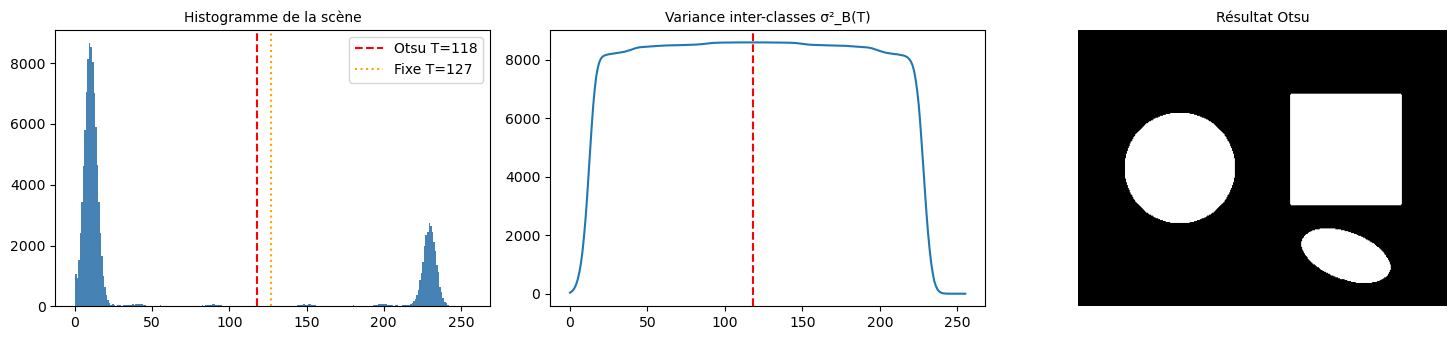

In [9]:
def otsu_manual(im):
    hist, _ = np.histogram(im.ravel(), bins=256, range=(0, 256))
    p = hist / hist.sum()
    omega = np.cumsum(p)
    mu = np.cumsum(p * np.arange(256))
    mu_t = mu[-1]
    with np.errstate(divide="ignore", invalid="ignore"):
        sigma_b = (mu_t * omega - mu) ** 2 / (omega * (1 - omega))
    sigma_b = np.nan_to_num(sigma_b)
    return int(np.argmax(sigma_b)), sigma_b

T_manual, sigma_b = otsu_manual(scene)
T_cv, scene_otsu = cv2.threshold(scene, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print(f"Seuil Otsu manuel = {T_manual} | OpenCV = {T_cv:.0f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].hist(scene.ravel(), bins=256, range=(0, 256), color="steelblue")
axes[0].axvline(T_cv, color="red", ls="--", label=f"Otsu T={T_cv:.0f}")
axes[0].axvline(127, color="orange", ls=":", label="Fixe T=127")
axes[0].legend(); axes[0].set_title("Histogramme de la scène")
axes[1].plot(sigma_b); axes[1].axvline(T_manual, color="red", ls="--")
axes[1].set_title("Variance inter-classes σ²_B(T)")
axes[2].imshow(scene_otsu, cmap="gray"); axes[2].set_title("Résultat Otsu"); axes[2].axis("off")
plt.tight_layout(); plt.show()

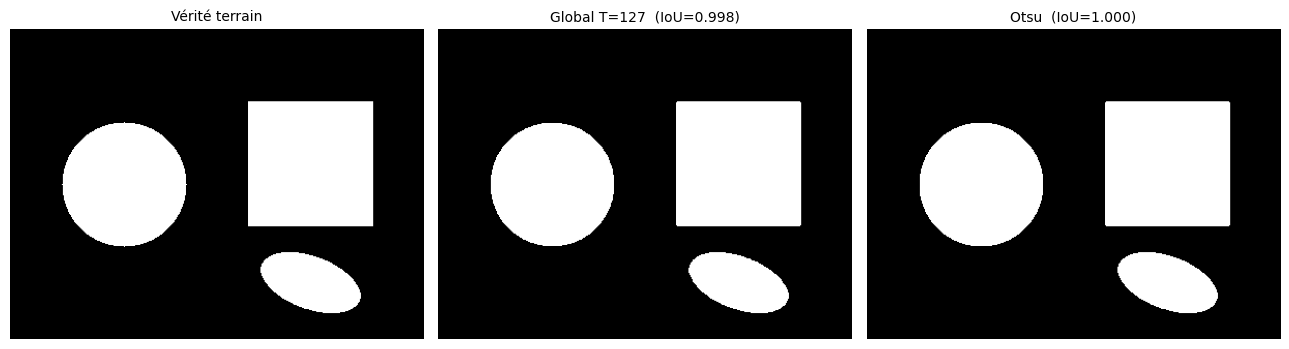

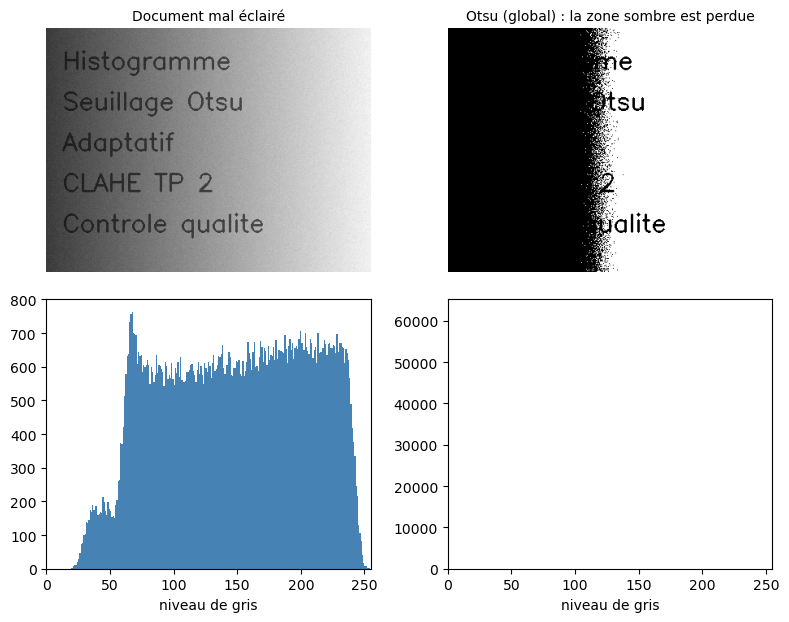

In [10]:
def iou(pred, gt):
    p, g = pred > 0, gt > 0
    return (p & g).sum() / max((p | g).sum(), 1)

_, glob = cv2.threshold(scene, 127, 255, cv2.THRESH_BINARY)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (t, r) in zip(axes, [("Vérité terrain", scene_gt), ("Global T=127", glob), ("Otsu", scene_otsu)]):
    ax.imshow(r, cmap="gray"); ax.axis("off")
    ax.set_title(t + ("" if t == "Vérité terrain" else f"  (IoU={iou(r, scene_gt):.3f})"))
plt.tight_layout(); plt.show()

# Sur le document mal éclairé : Otsu reste global
_, doc_otsu = cv2.threshold(DOC, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
show([DOC, doc_otsu], ["Document mal éclairé", "Otsu (global) : la zone sombre est perdue"])

**Observation :** Otsu retrouve seul un excellent seuil quand l'histogramme est bimodal. Mais il reste un seuil **unique** : il échoue dès que l'éclairage n'est pas uniforme.

## 2.3 Seuillage adaptatif (moyenne et gaussien)

Le seuil est calculé **pour chaque pixel** à partir de son voisinage `blockSize × blockSize` :

$$ T(x,y) = \text{moyenne (ou moyenne gaussienne pondérée) du voisinage} - C $$

- `ADAPTIVE_THRESH_MEAN_C` : moyenne simple
- `ADAPTIVE_THRESH_GAUSSIAN_C` : poids gaussiens (les pixels proches comptent plus) → plus lisse, moins sensible au bruit

Paramètres : `blockSize` (impair, > taille d'un détail), `C` (constante soustraite).

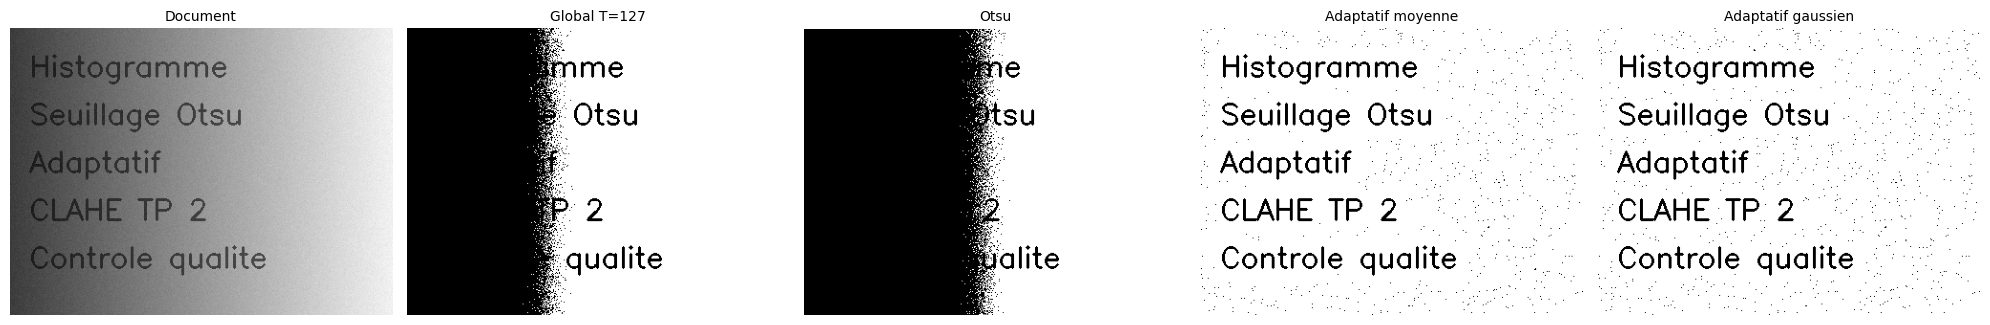

In [11]:
def thr_adaptive(im, method="gaussian", block=31, C=10):
    m = cv2.ADAPTIVE_THRESH_GAUSSIAN_C if method == "gaussian" else cv2.ADAPTIVE_THRESH_MEAN_C
    return cv2.adaptiveThreshold(im, 255, m, cv2.THRESH_BINARY, block, C)

show([DOC, thr_global(DOC, 127), doc_otsu, thr_adaptive(DOC, "mean"), thr_adaptive(DOC, "gaussian")],
     ["Document", "Global T=127", "Otsu", "Adaptatif moyenne", "Adaptatif gaussien"],
     hist=False, figsize=(20, 3.6))

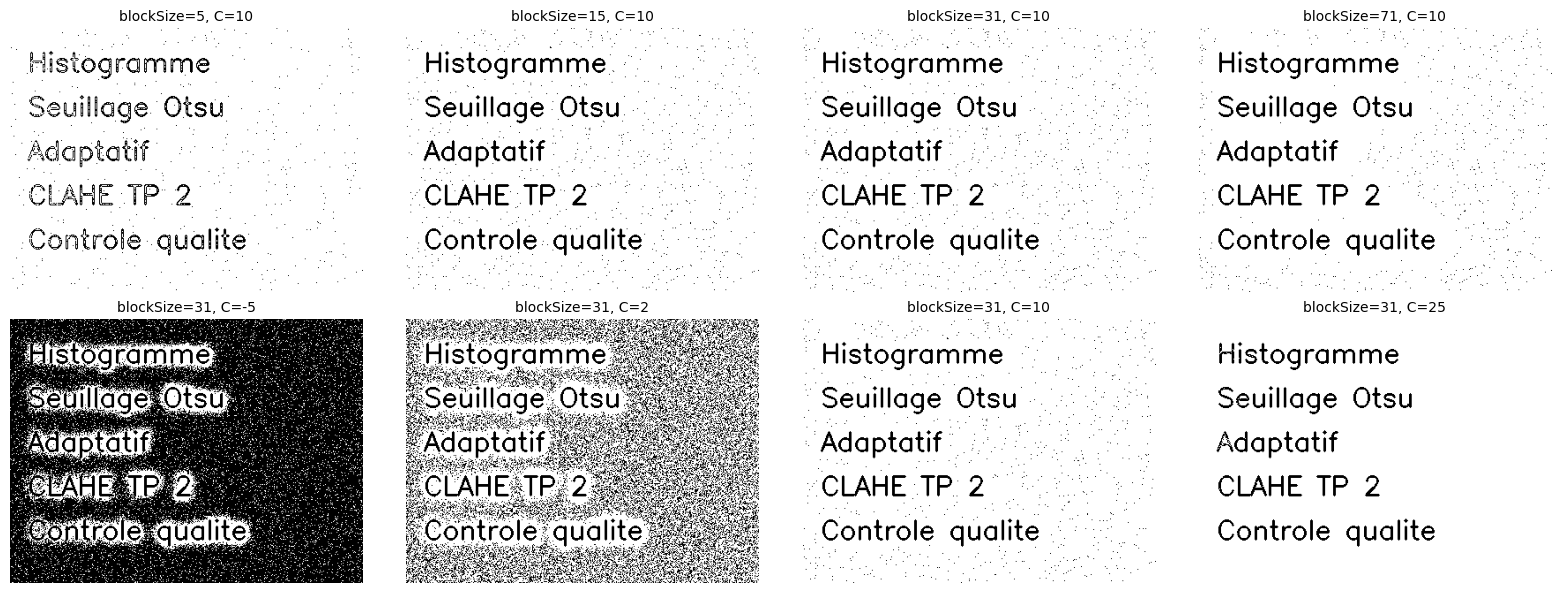

In [12]:
# Influence de blockSize et C (adaptatif gaussien)
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, block in zip(axes[0], [5, 15, 31, 71]):
    ax.imshow(thr_adaptive(DOC, "gaussian", block, 10), cmap="gray"); ax.set_title(f"blockSize={block}, C=10"); ax.axis("off")
for ax, C in zip(axes[1], [-5, 2, 10, 25]):
    ax.imshow(thr_adaptive(DOC, "gaussian", 31, C), cmap="gray"); ax.set_title(f"blockSize=31, C={C}"); ax.axis("off")
plt.tight_layout(); plt.show()

**Observations :**
- Le seuillage adaptatif **corrige le gradient d'éclairage** : le texte reste lisible partout.
- *Moyenne vs gaussien* : le gaussien donne un résultat plus propre (moins de « grain ») car il pondère le centre ; la moyenne est un peu plus bruitée mais plus rapide.
- `blockSize` trop **petit** → le seuil suit le bruit et les contours épais deviennent creux ; trop **grand** → on retombe vers un comportement global.
- `C` trop **faible** → le bruit du fond apparaît ; trop **grand** → le texte fin disparaît.
- Pour des **objets pleins** (cas industriel), `blockSize` doit dépasser la taille des objets ; pour du **texte fin** (document), un bloc de 15 à 51 convient.
- Dans les zones uniformes (fond), l'adaptatif n'a pas de contraste local et produit du bruit : c'est son principal défaut.

# Exercice 3 : Tableau récapitulatif

In [13]:
tableau = pd.DataFrame([
    ["Image sombre et homogène",
     "Étroit, concentré à gauche (niveaux bas)",
     "Étirement linéaire (ou égalisation globale)",
     "Le contenu est homogène : une transformation globale suffit. L'étirement ré-étale la plage sans déformer les rapports de luminosité ; l'égalisation donne plus de contraste mais amplifie davantage le bruit."],
    ["Image bruitée",
     "Étalé / lissé, modes mal séparés, vallée comblée",
     "Filtrage (gaussien / médian) AVANT, puis Otsu ; éviter l'égalisation",
     "L'égalisation amplifie le bruit. Lisser d'abord redonne un histogramme bimodal net, donc un seuil Otsu fiable. Un seuil adaptatif de petit bloc suivrait le bruit."],
    ["Document scanné mal éclairé",
     "Pics fond/texte étalés et décalés selon la zone (pas de vallée nette)",
     "Seuillage adaptatif gaussien",
     "L'éclairage varie dans l'image : un seuil global (même Otsu) sacrifie une partie. Le seuil local suit l'éclairage."],
    ["Image médicale",
     "Faible contraste, mode dominant étroit, structures utiles sur de petites plages",
     "CLAHE (puis Otsu / seuil sur zone si segmentation)",
     "Il faut révéler des détails locaux fins sans sur-amplifier le bruit ni créer d'artefacts ; CLAHE limite l'amplification (clipLimit) et travaille par tuiles."],
], columns=["Type d'image", "Histogramme", "Méthode la plus adaptée", "Pourquoi ?"])

pd.set_option("display.max_colwidth", None)
tableau.style.set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index")

Type d'image,Histogramme,Méthode la plus adaptée,Pourquoi ?
Image sombre et homogène,"Étroit, concentré à gauche (niveaux bas)",Étirement linéaire (ou égalisation globale),Le contenu est homogène : une transformation globale suffit. L'étirement ré-étale la plage sans déformer les rapports de luminosité ; l'égalisation donne plus de contraste mais amplifie davantage le bruit.
Image bruitée,"Étalé / lissé, modes mal séparés, vallée comblée","Filtrage (gaussien / médian) AVANT, puis Otsu ; éviter l'égalisation","L'égalisation amplifie le bruit. Lisser d'abord redonne un histogramme bimodal net, donc un seuil Otsu fiable. Un seuil adaptatif de petit bloc suivrait le bruit."
Document scanné mal éclairé,Pics fond/texte étalés et décalés selon la zone (pas de vallée nette),Seuillage adaptatif gaussien,L'éclairage varie dans l'image : un seuil global (même Otsu) sacrifie une partie. Le seuil local suit l'éclairage.
Image médicale,"Faible contraste, mode dominant étroit, structures utiles sur de petites plages",CLAHE (puis Otsu / seuil sur zone si segmentation),Il faut révéler des détails locaux fins sans sur-amplifier le bruit ni créer d'artefacts ; CLAHE limite l'amplification (clipLimit) et travaille par tuiles.


# Exercice 4 : CLAHE + seuillage

**CLAHE** (Contrast Limited Adaptive Histogram Equalization) :
1. l'image est découpée en tuiles (`tileGridSize`, ex. 8×8) ;
2. chaque tuile est égalisée séparément ;
3. l'histogramme de chaque tuile est **écrêté** à `clipLimit` : l'excédent est redistribué, ce qui limite l'amplification du bruit ;
4. les frontières entre tuiles sont lissées par interpolation bilinéaire.

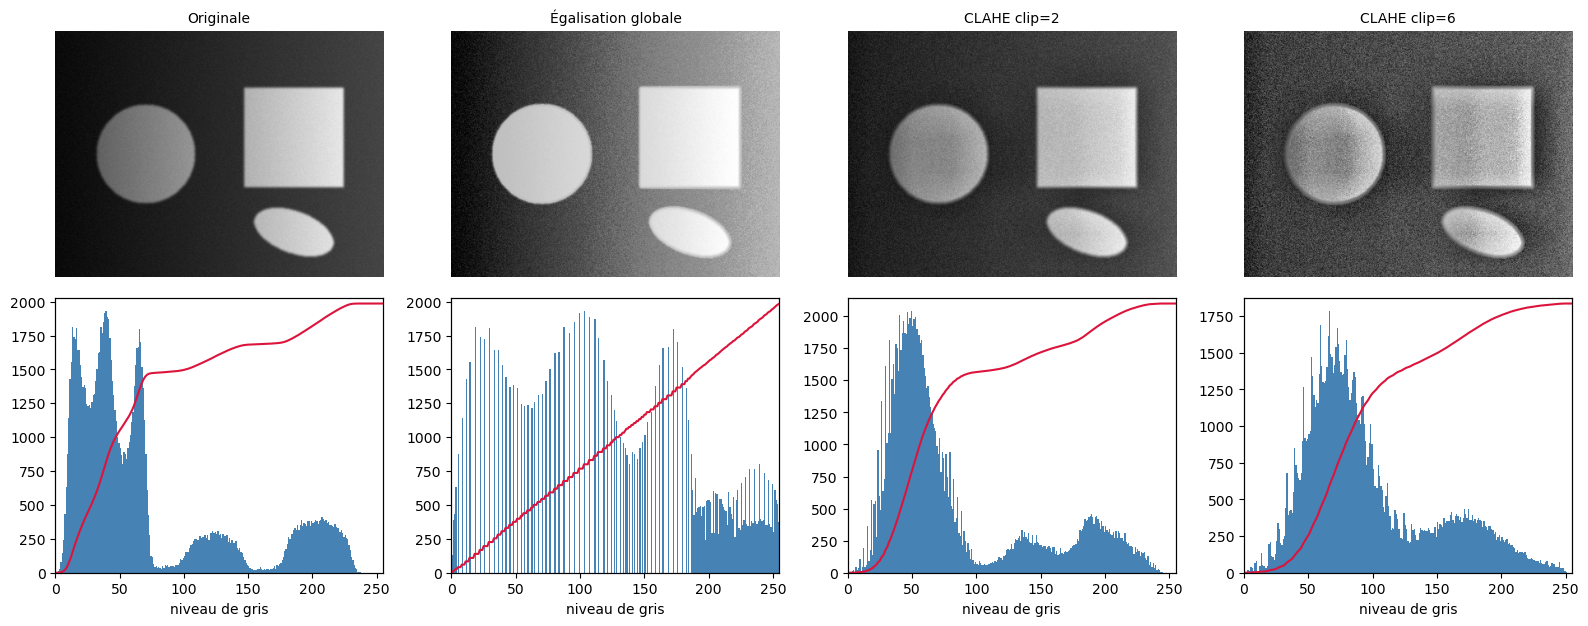

In [14]:
low_contrast, low_gt = SCENES["éclairage inégal"]
low_contrast = low_contrast if IMAGE_PATH is None else img   # votre image si fournie
low_gt = low_gt if IMAGE_PATH is None else None

def clahe(im, clip=2.0, tiles=(8, 8)):
    return cv2.createCLAHE(clipLimit=clip, tileGridSize=tiles).apply(im)

imgs = [low_contrast, cv2.equalizeHist(low_contrast), clahe(low_contrast, 2.0), clahe(low_contrast, 6.0)]
show(imgs, ["Originale", "Égalisation globale", "CLAHE clip=2", "CLAHE clip=6"], cdf=True)

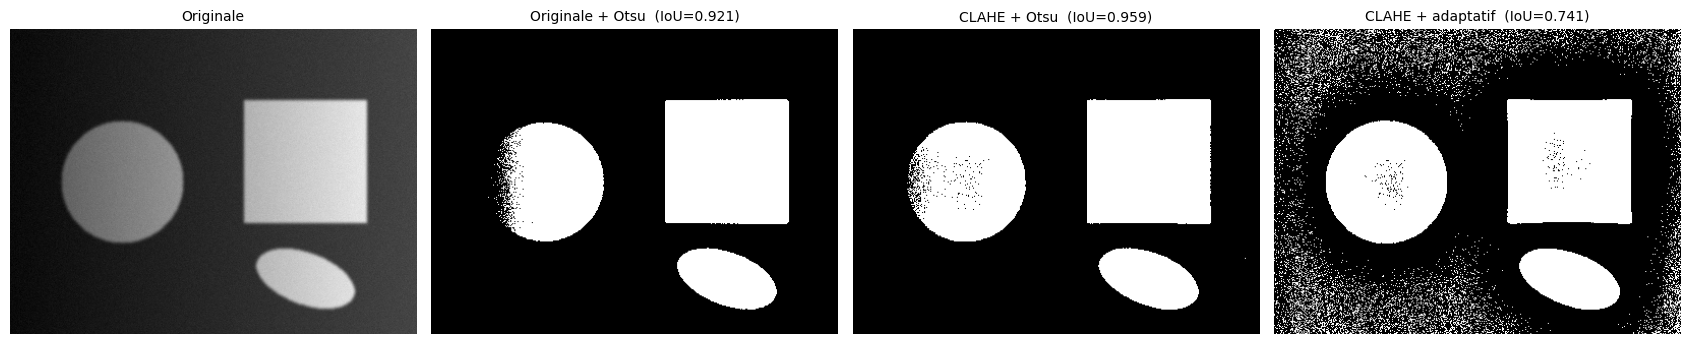

In [15]:
enh = clahe(low_contrast, 3.0)

results = {
    "Originale + Otsu":      cv2.threshold(low_contrast, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1],
    "CLAHE + Otsu":          cv2.threshold(enh, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1],
    "CLAHE + adaptatif":     thr_adaptive(enh, "gaussian", 251, -5),
}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
axes[0].imshow(low_contrast, cmap="gray", vmin=0, vmax=255); axes[0].set_title("Originale"); axes[0].axis("off")
for ax, (t, r) in zip(axes[1:], results.items()):
    ax.imshow(r, cmap="gray"); ax.axis("off")
    ax.set_title(t + (f"  (IoU={iou(r, low_gt):.3f})" if low_gt is not None else ""))
plt.tight_layout(); plt.show()

**Amélioration observée :** sans CLAHE, le gradient d'éclairage fait disparaître une partie des objets ; avec CLAHE, le contraste local est rétabli et Otsu (ou l'adaptatif) retrouve l'ensemble des objets. Le score IoU quantifie le gain.

---
# Problème : contrôle qualité industriel

**Contexte :** une caméra industrielle filme des produits ; selon l'éclairage, les images sont trop sombres / claires, peu contrastées, et l'objet se sépare mal du fond.
**Objectif :** améliorer l'image avec des techniques d'histogramme, puis extraire l'objet par un seuillage adapté.

## Partie 1 : Analyse et conception

Les quatre conditions simulées ci-dessous correspondent aux cas rencontrés en usine.

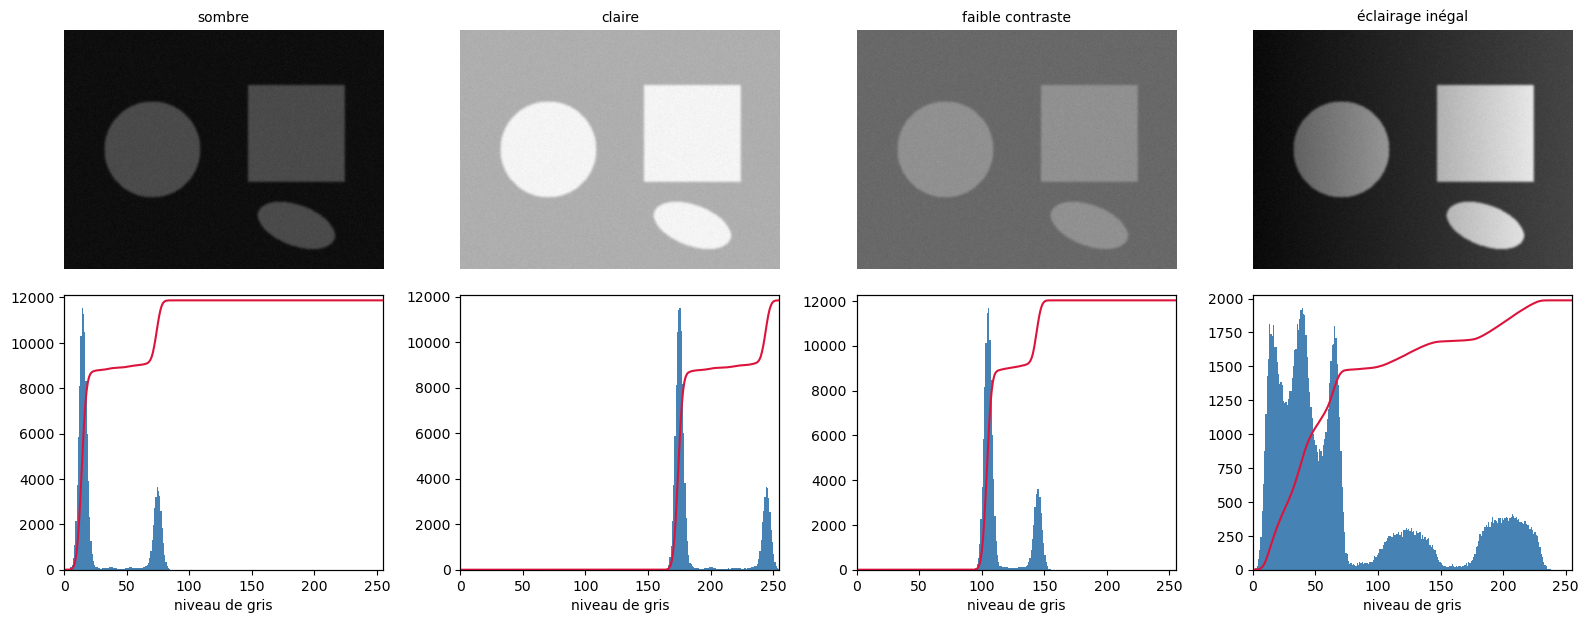

,Condition,Moyenne,Écart-type,Étendue (p95-p5)
0,sombre,29.5,25.7,67
1,claire,192.0,29.9,77
2,faible contraste,114.5,17.2,47
3,éclairage inégal,72.0,63.1,199


In [16]:
imgs = [SCENES[k][0] for k in CONDITIONS]
show(imgs, list(CONDITIONS), cdf=True, figsize=(16, 6.4))
rows = []
for k in CONDITIONS:
    im = SCENES[k][0]
    p5, p95 = np.percentile(im, [5, 95])
    rows.append([k, round(im.mean(), 1), round(im.std(), 1), int(p95 - p5)])
pd.DataFrame(rows, columns=["Condition", "Moyenne", "Écart-type", "Étendue (p95-p5)"])

### Q1. Que révèle l'histogramme ?

| Condition | Lecture de l'histogramme |
|---|---|
| Sombre | **écrasé à gauche** : moyenne basse, plage très étroite |
| Claire (surexposée) | **écrasé à droite** : tout est proche de 255, détails saturés |
| Faible contraste | **centré mais étroit** : les deux modes (fond/objet) sont très proches, vallée peu profonde |
| Éclairage inégal | **étalé et sans vallée nette** : les modes se chevauchent car le fond n'a pas une luminosité constante |

### Q2. Quelle technique d'amélioration ?

- **Étirement de contraste** : suffisant seulement si l'éclairage est uniforme et le problème est juste une plage étroite (cas sombre/clair/faible contraste *homogènes*). Rapide, sans artefacts, mais purement linéaire.
- **Égalisation globale** : améliore le contraste global mais une seule transformation pour toute l'image ; échoue si l'éclairage varie, et amplifie le bruit.
- **CLAHE** : **choix retenu** pour un contexte industriel, car les conditions d'éclairage varient dans l'image et d'une image à l'autre. Le contraste est rétabli *localement* avec une amplification limitée du bruit (`clipLimit`).

### Q3. Quelle méthode de seuillage après amélioration ?

- **Global fixe** : à écarter, `T` dépendrait de l'éclairage du jour.
- **Otsu** : **choix retenu** après CLAHE. L'amélioration rend l'histogramme bimodal, et Otsu calcule `T` automatiquement pour chaque image (robuste aux changements d'éclairage d'une image à l'autre).
- **Adaptatif** : à réserver au cas où il reste un gradient d'éclairage après CLAHE (variation lente), au prix de bruit dans les zones uniformes.

### Pipeline proposé

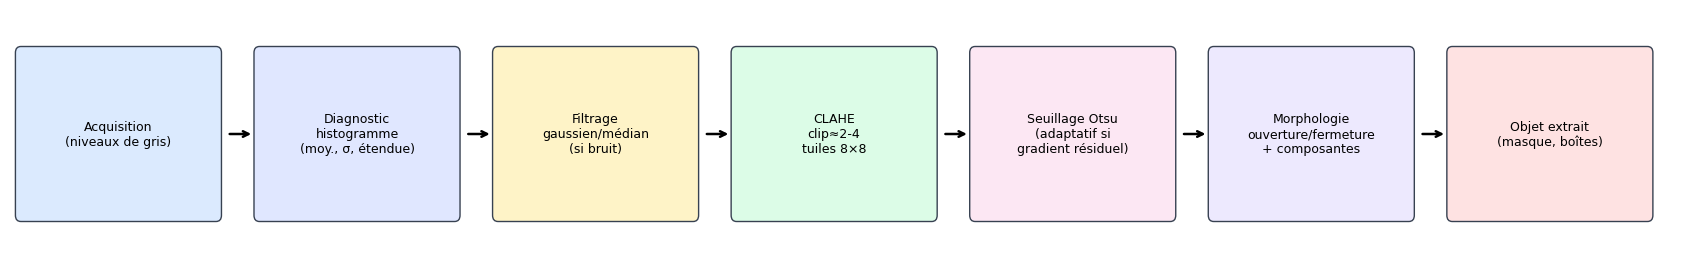

In [17]:
from matplotlib.patches import FancyBboxPatch

steps = [
    ("Acquisition\n(niveaux de gris)", "#dbeafe"),
    ("Diagnostic\nhistogramme\n(moy., σ, étendue)", "#e0e7ff"),
    ("Filtrage\ngaussien/médian\n(si bruit)", "#fef3c7"),
    ("CLAHE\nclip≈2-4\ntuiles 8×8", "#dcfce7"),
    ("Seuillage Otsu\n(adaptatif si\ngradient résiduel)", "#fce7f3"),
    ("Morphologie\nouverture/fermeture\n+ composantes", "#ede9fe"),
    ("Objet extrait\n(masque, boîtes)", "#fee2e2"),
]
fig, ax = plt.subplots(figsize=(17, 2.8))
ax.set_xlim(0, len(steps) * 2.2); ax.set_ylim(0, 2); ax.axis("off")
for i, (t, c) in enumerate(steps):
    x = i * 2.2 + 0.1
    ax.add_patch(FancyBboxPatch((x, 0.35), 1.8, 1.3, boxstyle="round,pad=0.05", fc=c, ec="#374151"))
    ax.text(x + 0.9, 1.0, t, ha="center", va="center", fontsize=9)
    if i < len(steps) - 1:
        ax.annotate("", xy=(x + 2.15, 1.0), xytext=(x + 1.9, 1.0), arrowprops=dict(arrowstyle="->", lw=1.8))
plt.tight_layout(); plt.show()

### Justification de chaque bloc

1. **Diagnostic** : la moyenne indique sombre/claire, l'écart-type ou l'étendue indique le contraste. Cela permet d'adapter automatiquement les paramètres.
2. **Filtrage** (optionnel) : l'amélioration de contraste amplifie le bruit ; on le réduit *avant*. Un filtre médian préserve les contours.
3. **CLAHE** : corrige luminosité *et* contraste localement, avec amplification du bruit bornée.
4. **Otsu** : seuil automatique, pas de réglage manuel, adapté à un histogramme devenu bimodal. Bascule vers adaptatif si un gradient persiste.
5. **Morphologie** : l'ouverture supprime les petits parasites, la fermeture bouche les trous dans l'objet.
6. **Extraction** : composantes connexes, boîtes englobantes, aire pour le contrôle qualité.

## Partie 2 : Implémentation Python

In [18]:
def diagnose(gray):
    p5, p95 = np.percentile(gray, [5, 95])
    d = dict(mean=gray.mean(), std=gray.std(), spread=p95 - p5)
    if d["mean"] < 85:
        d["luminosite"] = "sombre"
    elif d["mean"] > 170:
        d["luminosite"] = "claire"
    else:
        d["luminosite"] = "normale"
    d["contraste"] = "faible" if d["spread"] < 80 else "correct"
    return d

def enhance(gray, method="clahe", clip=3.0, tiles=(8, 8), denoise=True):
    if denoise:
        gray = cv2.medianBlur(gray, 3)
    if method == "none":
        return gray
    if method == "stretch":
        return stretch(gray, *np.percentile(gray, [2, 98]))
    if method == "equalize":
        return cv2.equalizeHist(gray)
    if method == "clahe":
        return cv2.createCLAHE(clipLimit=clip, tileGridSize=tiles).apply(gray)
    raise ValueError(method)

def segment(gray, method="otsu"):
    if method == "global":
        return cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)[1]
    if method == "otsu":
        return cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]
    if method == "adaptive":
        # blockSize > taille des objets (sinon l'intérieur plat des objets disparaît) ; C<0 : seuil = moyenne locale + 5
        return cv2.adaptiveThreshold(gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 251, -5)
    raise ValueError(method)

def clean_mask(mask, min_area=300):
    # l'objet est supposé minoritaire : on inverse si le masque couvre plus de la moitié
    if (mask > 0).mean() > 0.5:
        mask = cv2.bitwise_not(mask)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, k)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, k)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask)
    out = np.zeros_like(mask)
    for i in range(1, n):
        if stats[i, cv2.CC_STAT_AREA] >= min_area:
            out[labels == i] = 255
    return out

def pipeline(gray, enh="clahe", thr="otsu"):
    e = enhance(gray, enh)
    m = clean_mask(segment(e, thr))
    return e, m

def draw_boxes(gray, mask):
    vis = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    n, _, stats, cent = cv2.connectedComponentsWithStats(mask)
    for i in range(1, n):
        x, y, w, h, a = stats[i]
        cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
        cv2.putText(vis, f"{a}px", (x, max(y - 5, 12)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)
    return cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)

### Application du pipeline aux 4 conditions (CLAHE + Otsu)

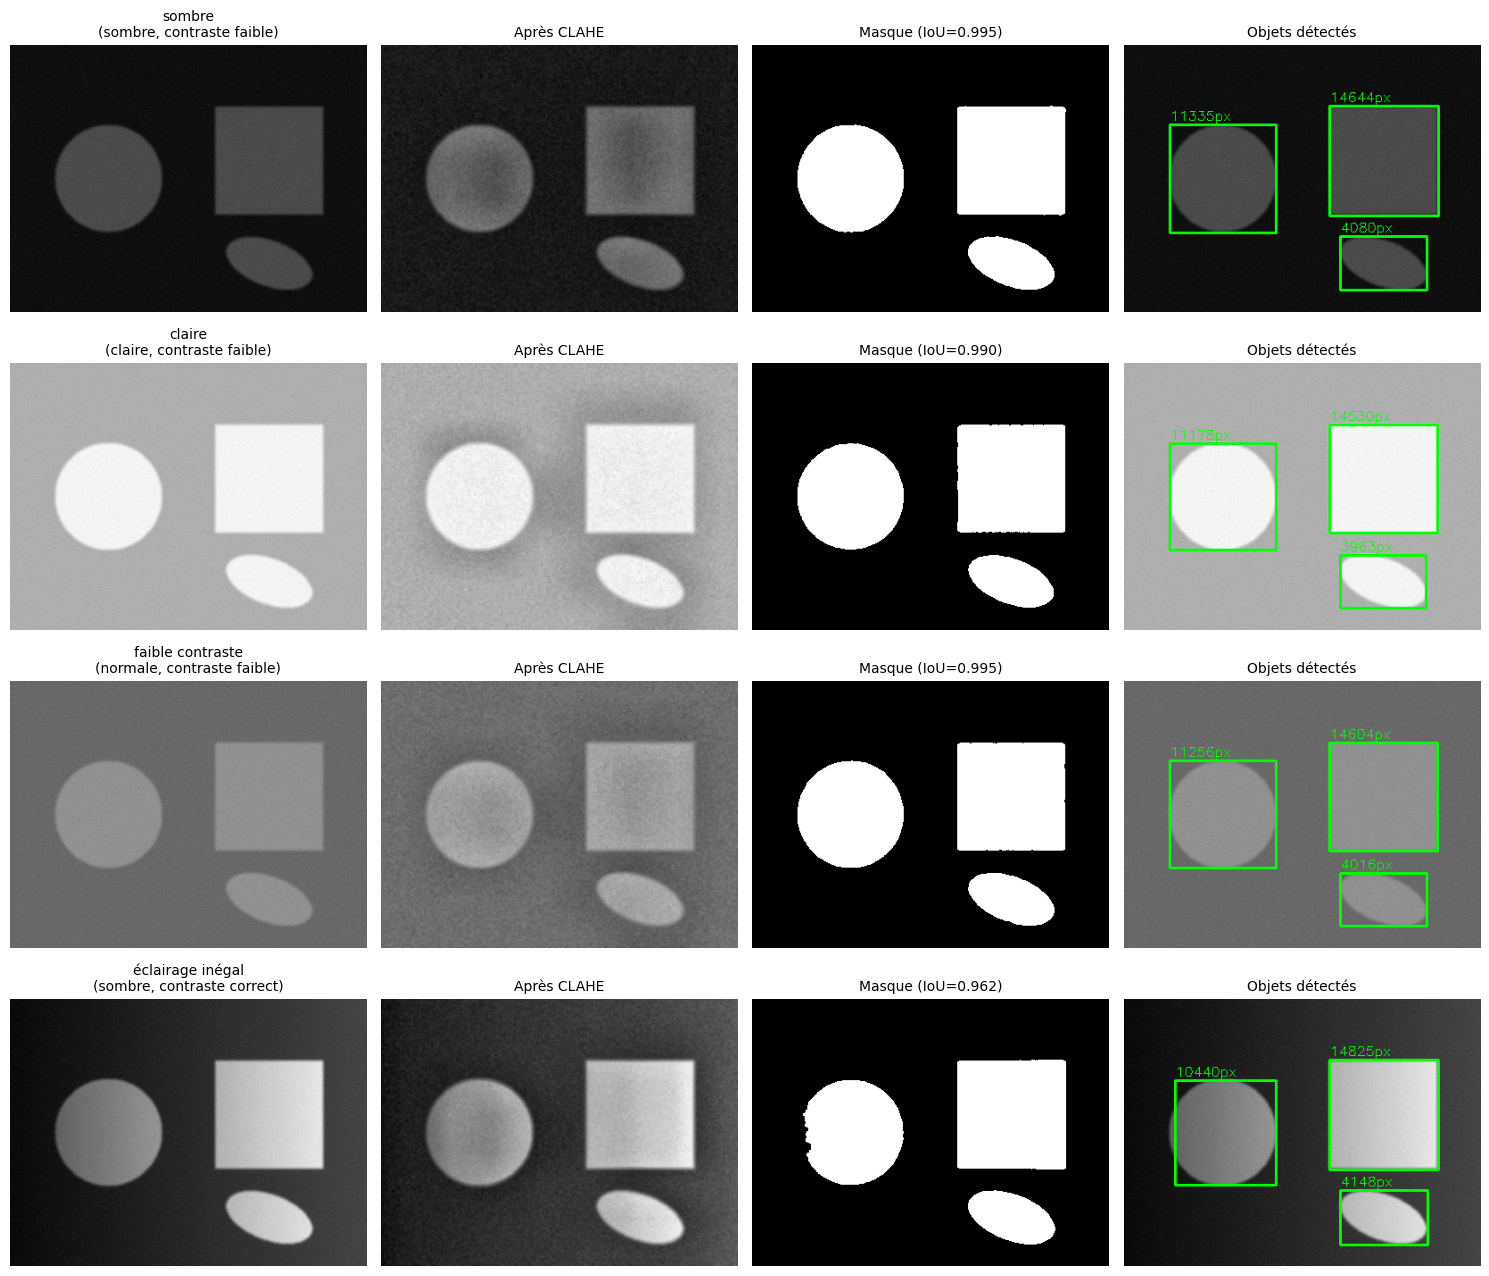

In [19]:
fig, axes = plt.subplots(4, 4, figsize=(15, 13))
for r, name in enumerate(CONDITIONS):
    im, gt = SCENES[name]
    d = diagnose(im)
    e, m = pipeline(im, "clahe", "otsu")
    axes[r, 0].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[r, 0].set_title(f"{name}\n({d['luminosite']}, contraste {d['contraste']})")
    axes[r, 1].imshow(e, cmap="gray", vmin=0, vmax=255); axes[r, 1].set_title("Après CLAHE")
    axes[r, 2].imshow(m, cmap="gray"); axes[r, 2].set_title(f"Masque (IoU={iou(m, gt):.3f})")
    axes[r, 3].imshow(draw_boxes(im, m)); axes[r, 3].set_title("Objets détectés")
    for a in axes[r]: a.axis("off")
plt.tight_layout(); plt.show()

### Comparaison systématique : 3 améliorations × 3 seuillages × 4 conditions

Grâce à la vérité terrain synthétique, on mesure l'**IoU** (intersection / union, 1 = parfait) de chaque combinaison.

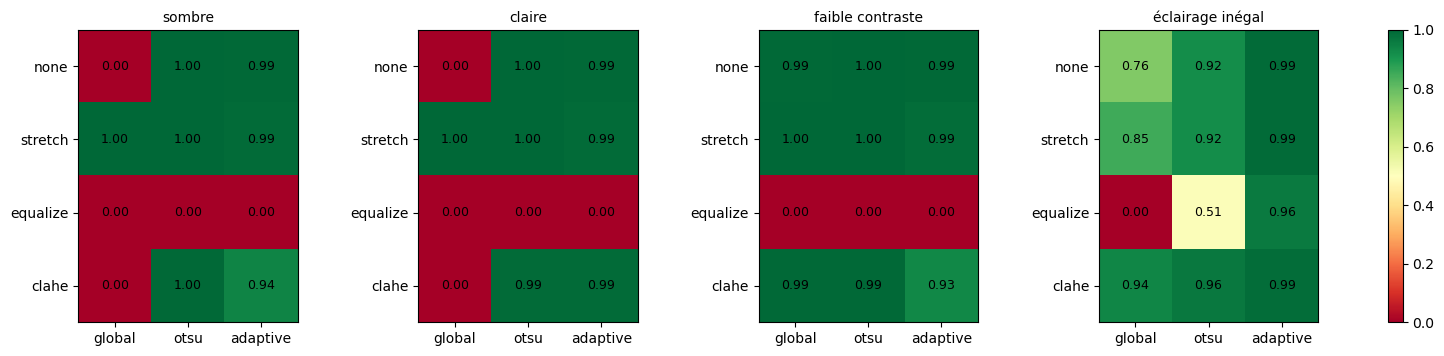

Meilleure combinaison par condition :


,condition,amélioration,seuillage,IoU
0,claire,stretch,otsu,0.998600
1,faible contraste,none,otsu,0.997101
2,sombre,none,otsu,0.998166
3,éclairage inégal,none,adaptive,0.991561



IoU moyen par combinaison (robustesse sur toutes les conditions) :


seuillage,global,otsu,adaptive
amélioration,,,
none,0.437,0.978,0.993
stretch,0.960,0.978,0.989
equalize,0.000,0.128,0.240
clahe,0.483,0.986,0.963


In [20]:
ENH = ["none", "stretch", "equalize", "clahe"]
THR = ["global", "otsu", "adaptive"]

records = []
for cond in CONDITIONS:
    im, gt = SCENES[cond]
    for e in ENH:
        for t in THR:
            _, m = pipeline(im, e, t)
            records.append(dict(condition=cond, amélioration=e, seuillage=t, IoU=iou(m, gt)))
res = pd.DataFrame(records)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, cond in zip(axes, CONDITIONS):
    piv = res[res.condition == cond].pivot(index="amélioration", columns="seuillage", values="IoU").loc[ENH, THR]
    im_ = ax.imshow(piv.values, vmin=0, vmax=1, cmap="RdYlGn")
    ax.set_xticks(range(len(THR))); ax.set_xticklabels(THR)
    ax.set_yticks(range(len(ENH))); ax.set_yticklabels(ENH)
    ax.set_title(cond)
    for i in range(len(ENH)):
        for j in range(len(THR)):
            ax.text(j, i, f"{piv.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.colorbar(im_, ax=axes, fraction=0.015)
plt.show()

best = res.loc[res.groupby("condition")["IoU"].idxmax()].reset_index(drop=True)
print("Meilleure combinaison par condition :")
display(best)

print("\nIoU moyen par combinaison (robustesse sur toutes les conditions) :")
display(res.groupby(["amélioration", "seuillage"])["IoU"].mean().unstack().loc[ENH, THR].round(3))

### Lecture des résultats

- **Otsu est invariant aux transformations affines de l'intensité** : sur une image sombre, claire ou peu contrastée mais *éclairée uniformément*, il trouve déjà le bon seuil sans amélioration préalable (IoU ≈ 1). L'étirement n'y change donc presque rien pour la segmentation, il améliore surtout l'affichage et la lisibilité.
- Le **seuil global fixe** (T = 127) échoue dès que la plage de gris ne le contient pas (sombre/claire/faible contraste) : il ne devient acceptable qu'après un étirement.
- **Éclairage inégal** : c'est le seul cas où Otsu seul perd (un seul seuil pour une image au fond variable). Ici l'adaptatif (grand bloc) et CLAHE + Otsu le corrigent.
- **Égalisation globale** : mauvais résultats. Le fond, majoritaire, occupe plus de la moitié de la plage aplatie et son bruit est étalé, donc Otsu coupe au milieu du fond : égaliser *avant* un seuillage est contre-productif sur ce type d'image.
- Le seuillage adaptatif exige un `blockSize` **plus grand que les objets** (ici 251 px) ; avec un petit bloc, l'intérieur uniforme des objets est confondu avec le fond.
- **Limite de la simulation** : le bruit ici est faible (σ ≈ 3 niveaux) et les objets sont pleins. Sur de vraies images industrielles, avec bruit, reflets et textures, l'amélioration locale (CLAHE) et les réglages du filtrage jouent un rôle plus important que ce que montre ce banc d'essai.

**Conclusion pour le choix de conception :** CLAHE + Otsu est la combinaison la plus *sûre* quand on ne contrôle pas l'éclairage (IoU moyen 0,986, sans réglage de blockSize), l'adaptatif seul est aussi très bon ici (0,993) mais dépend de `blockSize` et de `C` qu'il faut régler selon la taille des objets.

> Les chiffres exacts dépendent des images (ici synthétiques). Avec votre propre image, il n'y a pas de vérité terrain : l'IoU n'est pas calculable, mais la comparaison visuelle reste valable.

### Pipeline automatique avec choix guidé par le diagnostic

In [21]:
def auto_pipeline(gray):
    """Choisit les paramètres selon le diagnostic de l'histogramme."""
    d = diagnose(gray)
    clip = 4.0 if d["contraste"] == "faible" else 2.0
    e = enhance(gray, "clahe", clip=clip)
    # Si la variance du fond (mesurée sur un flou fort) est grande, l'éclairage est inégal : adaptatif
    bg = cv2.GaussianBlur(e, (0, 0), 40)
    thr = "adaptive" if bg.std() > 25 else "otsu"
    return d, thr, e, clean_mask(segment(e, thr))

for name in CONDITIONS:
    im, gt = SCENES[name]
    d, thr, e, m = auto_pipeline(im)
    print(f"{name:18s} -> {d['luminosite']:8s} contraste {d['contraste']:8s} | seuillage choisi : {thr:8s} | IoU = {iou(m, gt):.3f}")

sombre             -> sombre   contraste faible   | seuillage choisi : otsu     | IoU = 0.995
claire             -> claire   contraste faible   | seuillage choisi : otsu     | IoU = 0.980
faible contraste   -> normale  contraste faible   | seuillage choisi : otsu     | IoU = 0.990
éclairage inégal   -> sombre   contraste correct  | seuillage choisi : adaptive | IoU = 0.989


## Conclusion

- L'histogramme est l'**outil de diagnostic** : sa position, sa largeur et sa modalité dictent le traitement.
- **Étirement** : simple et sûr si l'éclairage est homogène. **Égalisation** : contraste fort mais sensible au bruit. **CLAHE** : le meilleur compromis pour un éclairage variable.
- **Otsu** automatise le choix du seuil quand l'histogramme est bimodal (après amélioration) ; l'**adaptatif** est la réponse aux variations d'éclairage spatiales.
- Pour l'industrie : **diagnostic → (filtrage) → CLAHE → Otsu (ou adaptatif) → morphologie → extraction**.